# Step 5: Look closely at the target

**Goal:** understand the 6-month net spend before choosing a model. This step is **analysis only**: the target is not changed. The logic is in `src/step5_target.py`.

Questions:
1. How is the target made up (zeros / negatives / positives)?
2. Who are the negative-target customers, and what would flooring at 0 change?
3. How skewed is it, and how concentrated is the money?
4. Is "buys again or not" predictable from RFM?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF, TEST_CUTOFF
from step4_rfm import build_rfm
from step5_target import composition, negative_customers, concentration, repurchase_rates

pd.set_option("display.width", 160)
ledger = load_ledger()
train = make_snapshot(ledger, TRAIN_CUTOFF)
test = make_snapshot(ledger, TEST_CUTOFF)
rfm_train, rfm_test = build_rfm(train), build_rfm(test)

## 1. Composition: zero, negative, positive

In [2]:
comp = pd.DataFrame({"train": composition(train.target_net), "test": composition(test.target_net)})  # before flooring
display(comp)
print("Percentiles of the POSITIVE targets (GBP):")
display(pd.DataFrame({"train": train.target[train.target > 0].quantile([.1, .25, .5, .75, .9, .99]),
                      "test": test.target[test.target > 0].quantile([.1, .25, .5, .75, .9, .99])}).round(0))

,train,test
customers,4242,4326
zero,2152,1837
negative,51,28
positive,2039,2461


Percentiles of the POSITIVE targets (GBP):


,train,test
0.10,156.0,160.0
0.25,290.0,310.0
0.50,604.0,648.0
0.75,1321.0,1446.0
0.90,2833.0,2932.0
0.99,15777.0,17261.0


## 2. The negative targets

A negative target means the customer got back more money than they spent in the target window. Look at how much they bought vs returned there.

In [3]:
neg = negative_customers(train, ledger)  # uses target_net (unfloored)
display(neg.describe().round(0).loc[["count", "mean", "min", "max"]])
print("Worst 5 (train):")
display(neg.nsmallest(5, "net").round(0))
for name, s in [("train", train), ("test", test)]:
    tn = s.target_net
    print(f"{name}: sum of negatives {tn[tn < 0].sum():,.0f} | mean target unfloored {tn.mean():,.1f} -> floored at 0: {s.target.mean():,.1f}")

,bought_in_window,returned_in_window,net
count,51.0,51.0,51.0
mean,44.0,-182.0,-138.0
min,0.0,-2384.0,-2384.0
max,1087.0,-1.0,-1.0


Worst 5 (train):


,bought_in_window,returned_in_window,net
Customer ID,,,
14213,0.0,-2384.0,-2384.0
15823,0.0,-812.0,-812.0
16546,1087.0,-1766.0,-680.0
16252,0.0,-590.0,-590.0
17307,0.0,-305.0,-305.0


train: sum of negatives -7,045 | mean target unfloored 712.3 -> floored at 0: 713.9
test: sum of negatives -1,658 | mean target unfloored 957.6 -> floored at 0: 958.0


They are mostly refunds of goods bought *earlier* (before the target window), with little or no new buying. Flooring at 0 changes the mean target by about 0.2%, i.e. almost nothing, and only 1.2% / 0.6% of customers are affected.

## 3. Skew and concentration

train: skewness raw 19.0 | log1p(floored at 0) 0.25 | mean 714 -> without top 10 customers 589
test: skewness raw 23.2 | log1p(floored at 0) -0.06 | mean 958 -> without top 10 customers 757


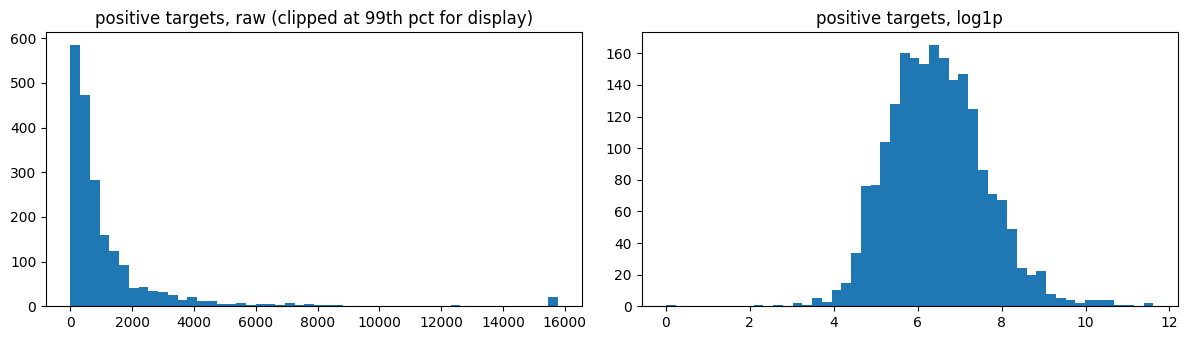

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
pos = train.target[train.target > 0]
axes[0].hist(pos.clip(upper=pos.quantile(0.99)), bins=50, color="tab:blue")
axes[0].set_title("positive targets, raw (clipped at 99th pct for display)")
axes[1].hist(np.log1p(pos), bins=50, color="tab:blue")
axes[1].set_title("positive targets, log1p")
plt.tight_layout()

for name, s in [("train", train), ("test", test)]:
    t = s.target
    print(f"{name}: skewness raw {t.skew():.1f} | log1p(floored at 0) {np.log1p(t.clip(lower=0)).skew():.2f}"
          f" | mean {t.mean():,.0f} -> without top 10 customers {t.drop(t.nlargest(10).index).mean():,.0f}")

Raw: a long right tail (skewness about 19-23). After `log1p` it is roughly symmetric (skewness near 0). Now, how concentrated is the money among customers who buy?

,train,test
top 1% of positive-target customers,25%,30%
top 5% of positive-target customers,44%,48%
top 10% of positive-target customers,56%,58%
top 20% of positive-target customers,70%,71%


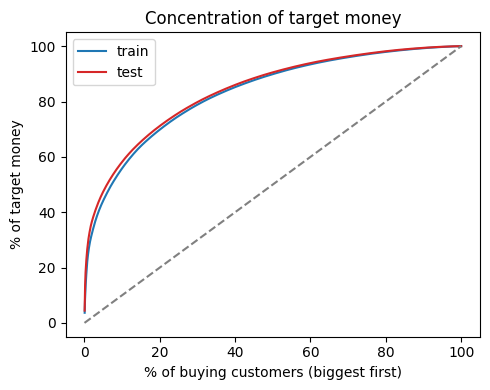

In [5]:
conc = pd.DataFrame({"train": concentration(train.target), "test": concentration(test.target)})
display(conc.map(lambda v: f"{v:.0%}"))

fig, ax = plt.subplots(figsize=(5, 4))
for name, s, c in [("train", train, "tab:blue"), ("test", test, "tab:red")]:
    p = s.target[s.target > 0].sort_values(ascending=False).values
    ax.plot(np.arange(1, len(p) + 1) / len(p) * 100, p.cumsum() / p.sum() * 100, color=c, label=name)
ax.plot([0, 100], [0, 100], "--", color="gray")
ax.set_xlabel("% of buying customers (biggest first)"); ax.set_ylabel("% of target money")
ax.set_title("Concentration of target money"); ax.legend()
plt.tight_layout()

## 4. Is "buys again or not" predictable?

Share of customers with target > 0, by Frequency bucket and by Recency quartile.

train        test      
                           mean  size  mean  size
Frequency 1                0.24  1423  0.34  1552
          2                0.37   806  0.49   812
          3-5              0.58  1131  0.69  1125
          6-10             0.82   581  0.88   524
          11+              0.92   301  0.95   313
Recency   R1 most recent   0.70  1071  0.83  1083
          R2               0.53  1062  0.65  1085
          R3               0.44  1049  0.48  1084
          R4 least recent  0.25  1060  0.32  1074

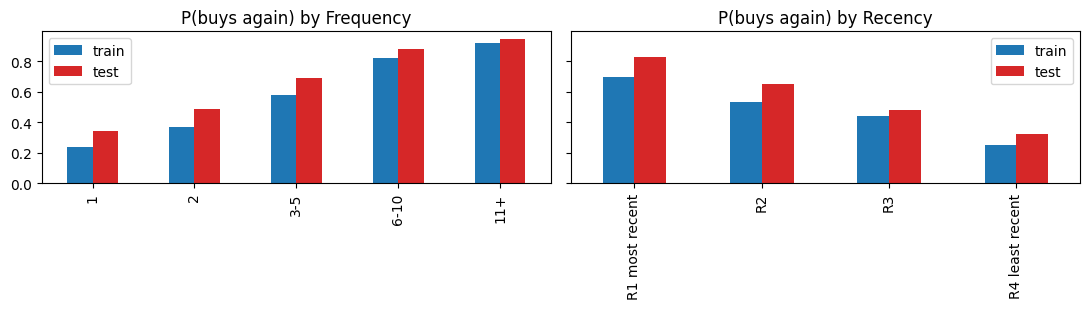

In [6]:
rr = pd.concat({"train": repurchase_rates(rfm_train, train.target),
                "test": repurchase_rates(rfm_test, test.target)}, axis=1).round(2)
display(rr)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, key in zip(axes, ["Frequency", "Recency"]):
    x = pd.DataFrame({"train": rr.loc[key][("train", "mean")], "test": rr.loc[key][("test", "mean")]})
    x.plot(kind="bar", ax=ax, color=["tab:blue", "tab:red"]); ax.set_title(f"P(buys again) by {key}"); ax.set_xlabel("")
plt.tight_layout()

## What we learned

- **Zeros:** about 52% (train) / 43% (test) of customers buy nothing in the next 6 months (after flooring). The median train target is 0.
- **Whether they buy again is very predictable from RFM:** one-time buyers return 24% (train) of the time, customers with 11+ orders 92%. Recency tells the same story (70% for the most recent quarter vs 25% for the least recent). So "will they buy?" and "how much?" are two different questions, and a two-stage (hurdle) model is natural.
- **Negatives:** 51 / 28 customers, almost all refunds of earlier purchases. Flooring at 0 changes the mean target by about 0.2%.
- **Skew:** raw skewness 19-23. `log1p` makes it near-symmetric. The top 10% of buying customers hold 56-58% of the money, the top 20% about 70%.
- **Outliers:** removing just the top 10 customers drops the mean target from 714 to 589 (train) and 958 to 757 (test). Evaluation on a raw-money scale will be sensitive to a handful of people.

## Decisions taken (now applied in `src/step3_split.py`)
1. **Negatives: floor at 0.** A customer is never worth less than nothing, and the effect on the mean is about 0.2%. The unfloored value stays available as `snapshot.target_net`.
2. **Scale to model: try more than one.** Step 7 compares four target treatments on the same features, all scored on the original money scale: raw money, `log1p`, Tweedie, and a two-stage Hurdle.
3. **Outliers: keep everyone, no clipping.** Metrics will be reported with and without the top customers.

**Next (step 6):** baselines (predict the mean; rank by past spend) before any machine learning, so we know what a model has to beat.